In [3]:
import pandas as pd

df = pd.read_csv("../data/raw/data.csv", sep=";")
print(df.shape)
print(df["Target"].value_counts())
df.head()

(4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
df.info()
print("Missing value:", df.isna().sum().sum())
print("Duplikat:", df.duplicated().sum())
df.describe().T.head(15)

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


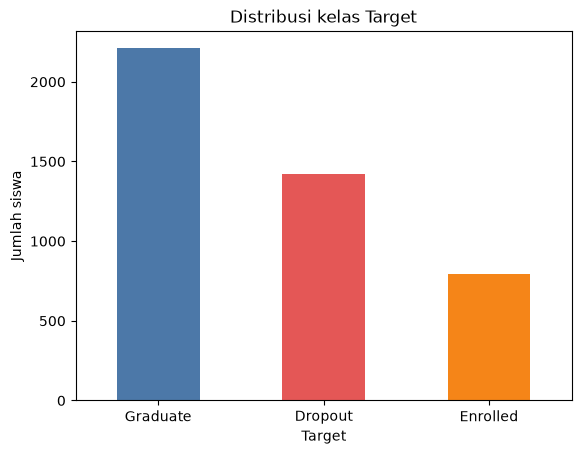

Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64


In [5]:
import matplotlib.pyplot as plt

ax = df["Target"].value_counts().plot(kind="bar", color=["#4c78a8", "#e45756", "#f58518"])
ax.set_title("Distribusi kelas Target")
ax.set_ylabel("Jumlah siswa")
plt.xticks(rotation=0)
plt.show()

print((df["Target"].value_counts(normalize=True) * 100).round(1))

In [6]:
import pandas as pd

for kolom in ["Tuition fees up to date", "Scholarship holder", "Debtor"]:
    print(f"\n{kolom} (persen per Target)")
    print((pd.crosstab(df[kolom], df["Target"], normalize="index") * 100).round(1))


Tuition fees up to date (persen per Target)
Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
0                           86.6       8.0       5.5
1                           24.7      19.3      56.0

Scholarship holder (persen per Target)
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      38.7      20.0      41.3
1                      12.2      11.8      76.0

Debtor (persen per Target)
Target  Dropout  Enrolled  Graduate
Debtor                             
0          28.3      18.0      53.8
1          62.0      17.9      20.1


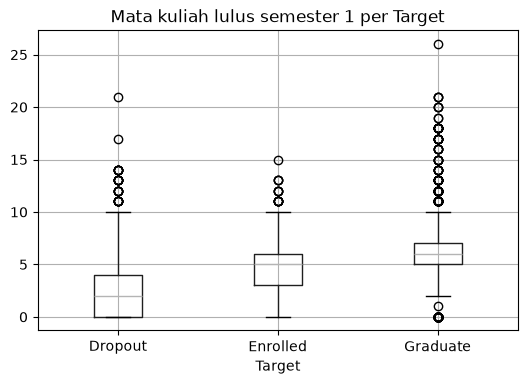

In [7]:
df.boxplot(column="Curricular units 1st sem (approved)", by="Target", figsize=(6, 4))
plt.suptitle("")
plt.title("Mata kuliah lulus semester 1 per Target")
plt.show()

In [8]:
df["dropout"] = (df["Target"] == "Dropout").astype(int)

print(df["dropout"].value_counts())
print((df["dropout"].value_counts(normalize=True) * 100).round(1))

dropout
0    3003
1    1421
Name: count, dtype: int64
dropout
0    67.9
1    32.1
Name: proportion, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Target", "dropout"])
y = df["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

train = X_train.copy()
train["dropout"] = y_train
test = X_test.copy()
test["dropout"] = y_test

train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)

print("Train:", train.shape, "| proporsi dropout:", round(y_train.mean(), 3))
print("Test :", test.shape, "| proporsi dropout:", round(y_test.mean(), 3))

Train: (3539, 37) | proporsi dropout: 0.321
Test : (885, 37) | proporsi dropout: 0.321
